# GenAI FinOps — reproducing the report's figures

**CAS ETH in Machine Learning in Finance and Insurance · Innovation Project · Albert Escriche**

This notebook recomputes every number that appears in the project report and in the
presentation, from the constants fixed in the annexes. It is not a product: the Innovation
Project is a framework study, and this notebook exists so that a reader can check the
arithmetic rather than take it on trust.

Run it top to bottom. It needs only `numpy` and `matplotlib`, no network and no API key.
The last cell asserts each published figure and prints a pass/fail table; if the notebook
runs to the end without raising, every figure in the report has been reproduced.

| Section | Reproduces |
|---|---|
| 1 | Constants and their annex sources |
| 2 | Adoption S-curve — phase lengths, adopters, peak load (Annex F) |
| 3 | Hardware tiers — rented against owned, per month (Annexes D, G) |
| 4 | The cost model — service, infrastructure, workforce |
| 5 | The underwriting case — the four infrastructure models (Chapter 5.3) |
| 6 | Workforce — pensum by phase, and the switching threshold (Annex H) |
| 7 | The three use cases and their recommendations (Chapter 5.5) |
| 8 | Economy of scale — cost per million tokens and the crossover (Chapter 6.4) |
| 9 | The blended path across adoption phases |
| 10 | Assertions against every published figure |

## 1 · Constants

Every value below is fixed in an annex of the report; the comment names it.

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.grid": True,
                     "grid.color": "#e2e7e9", "axes.edgecolor": "#8d9ba5",
                     "axes.spines.top": False, "axes.spines.right": False})
INK, TEAL, AMBER, SLATE, RED, BLUE = "#15232b", "#0b6e7f", "#d98324", "#4a5c6a", "#9e2a2b", "#2563a8"

# ── currency and hardware economics ────────────────────────────────── Annex G.1
FX      = 0.8321   # USD → CHF, mid rate 12 October 2026
UPLIFT  = 1.40     # Dell APEX subscription uplift over outright purchase   Annex D.1
TERM    = 36       # months: APEX term and Azure reservation term           Annex F.2
KWH     = 0.20     # CHF per kWh, Swiss commercial                          Annex D.3
HOURS   = 730      # hours in a month, always on                            Annex G.2
COLO    = 1250     # CHF per server-month, Swisscom colocation              Annex D.3

# ── workload shape ─────────────────────────────────────────────────── Annex F.3
WORK_DAYS    = 22      # working days a month
WORK_SECONDS = 28800   # eight working hours, in seconds
PEAK         = 3       # peak load over the average, within the working day
MONTHS       = 36      # the horizon of the comparison

# ── adoption, Bass diffusion ───────────────────────────────────────── Annex F.1
BASS_P, BASS_Q = 0.03, 0.38   # innovation and imitation, per quarter
PHASE_LO, PHASE_HI = 0.16, 0.84   # early → mid → long-term boundaries

# ── salaries, CHF per month including a 15% employer loading ───────── Annex H.2
SALARY = dict(prompt=9111, ai=12698, appdev=12419, mlops=11174, cloud=13866, sre=12419)
ROLE   = dict(prompt="Prompt engineer", ai="AI engineer", appdev="Application developer",
              mlops="MLOps engineer", cloud="Cloud engineer", sre="Site reliability engineer")

# Pensum per role, by adoption phase [early, mid, long-term].             Annex H.3
# Owned AI carries no infrastructure engineer: Dell maintains the hardware under the
# APEX subscription and Swisscom provides the data-centre layer.
FTE = {"aiaas":   {"prompt": [.3, .3, .3]},
       "gateway": {"ai": [.2, .4, .5], "appdev": [.3, .5, .5]},
       "hyper":   {"mlops": [.5, .7, 1], "cloud": [.3, .5, .5],
                   "sre": [.3, .5, 1],   "appdev": [.3, .5, .5]},
       "owned":   {"mlops": [.5, .7, 1], "sre": [.5, 1, 1.5], "appdev": [.3, .5, .5]}}

# One-time build cost, CHF                                                Annex H.4
SETUP = dict(aiaas=9111, gateway=37535, hyper=73470, owned=59605)

# ── AI as a Service, Microsoft 365 Copilot ─────────────────────────── Annex B.1
SEAT              = 25      # CHF per user per month (USD 30 at 0.8321)
CREDIT_PACK       = 166     # CHF per pack per month
CREDITS_PER_PACK  = 25000
CREDITS_PER_ANSWER = 10     # tenant-graph grounded agent            Annex B, Table B1

# ── the three LLM tiers ──────────────────────── Annexes A.2, C.1, D.2, G.2
# azure  : CHF per month, Switzerland North, pay-as-you-go list, 730 hours
# vm_tok_s: tokens per second the matching GPU configuration serves
# card/chassis in USD; kw is the server's draw under load
TIERS = {
 1: dict(name="Tier 1 — Small",    params="~8B",
         model="gpt-5.4-mini", price_in=0.21,  price_out=1.66,  open="Apertus 8B",
         vm="NC24ads A100 v4",  azure=3190,  vm_tok_s=2500,
         box="PowerEdge R760xa · 1× L40S",   gpus=1, card=10000, chassis=25000, kw=0.6),
 2: dict(name="Tier 2 — Medium",   params="~70B",
         model="gpt-5.4",      price_in=2.08,  price_out=12.48, open="Llama 3.3 70B",
         vm="NC80adis H100 v5", azure=12126, vm_tok_s=2400,
         box="PowerEdge R760xa · 2× H100 NVL", gpus=2, card=29000, chassis=30000, kw=1.6),
 3: dict(name="Tier 3 — Frontier", params="671B total / 37B active",
         model="gpt-5.4-pro",  price_in=12.48, price_out=49.93, open="DeepSeek-V3",
         vm="ND96isr H100 v5",  azure=85404, vm_tok_s=5500,
         box="PowerEdge XE9680 · 8× H100",   gpus=8, card=29000, chassis=60000, kw=6.5)}

INFRA = dict(aiaas="AI as a Service", gateway="GenAI Gateway",
             hyper="Hyperscaled AI",  owned="Owned AI")
KINDS = ["aiaas", "gateway", "hyper", "owned"]

chf = lambda n: f"CHF {round(n):,}".replace(",", "'")
print("constants loaded ·", len(SALARY), "roles ·", len(TIERS), "tiers")

constants loaded · 6 roles · 3 tiers


## 2 · Adoption

A new internal application is not used by everyone on day one. The report models take-up with
the Bass diffusion curve (Annex F.1):

$$F(t)=\frac{1-e^{-(p+q)t}}{1+\frac{q}{p}e^{-(p+q)t}}$$

with $p=0.03$ and $q=0.38$ per quarter. The curve is cut into three phases at 16% and 84% of
the intended population, which is what the report calls early adoption, mid adoption and
long-term use.

In [2]:
def bass(t, p=BASS_P, q=BASS_Q):
    e = math.exp(-(p + q) * t)
    return (1 - e) / (1 + (q / p) * e)

def phase_of(f):
    return 0 if f < PHASE_LO else (1 if f < PHASE_HI else 2)

def month_rows(users, tasks_per_day, tokens_in, tokens_out):
    # One row per month: adopters, tokens, and the peak load they imply.
    rows = []
    for m in range(MONTHS):
        t = (m + 0.5) / 3                       # months → quarters, mid-month
        f = bass(t)
        adopters = max(round(users * f), 1)
        per_task = tokens_in + tokens_out
        daily = adopters * tasks_per_day * per_task
        rows.append(dict(
            m=m, f=f, phase=phase_of(f), adopters=adopters,
            answers   = adopters * tasks_per_day * WORK_DAYS,
            tokens_in = adopters * tasks_per_day * tokens_in  * WORK_DAYS,
            tokens_out= adopters * tasks_per_day * tokens_out * WORK_DAYS,
            monthly   = daily * WORK_DAYS,
            peak      = daily * PEAK / WORK_SECONDS))        # tokens per second
    return rows

# the underwriting assistant of Chapter 5.3
UW = dict(users=300, tasks_per_day=20, tokens_in=5000, tokens_out=1000)
rows = month_rows(**UW)

lengths = [sum(1 for r in rows if r["phase"] == i) for i in range(3)]
last = rows[-1]
print("phase lengths, months      :", lengths)
print("adopters at month 36       :", last["adopters"], f"of {UW['users']}")
print("peak load at month 36      :", f"{last['peak']:,.0f} tokens/second")
print("tokens over three years    :", f"{sum(r['monthly'] for r in rows)/1e9:,.2f} billion")

phase lengths, months      : [9, 22, 5]
adopters at month 36       : 271 of 300
peak load at month 36      : 3,388 tokens/second
tokens over three years    : 12.72 billion


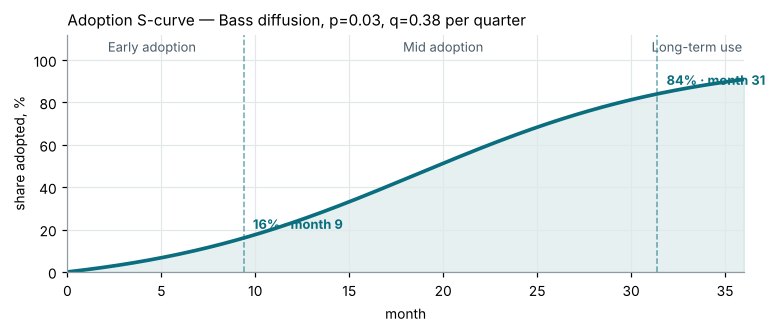

In [3]:
fig, ax = plt.subplots(figsize=(7.2, 3.1))
t = np.linspace(0, 12, 400)
f = [bass(x) for x in t]
ax.plot(t * 3, np.array(f) * 100, color=TEAL, lw=2.4)
ax.fill_between(t * 3, 0, np.array(f) * 100, color=TEAL, alpha=.10)
for b, lab in ((PHASE_LO, "16%"), (PHASE_HI, "84%")):
    x = next(x for x in t if bass(x) >= b) * 3
    ax.axvline(x, color=TEAL, ls="--", lw=1, alpha=.6)
    ax.annotate(f"{lab} · month {x:.0f}", (x, b * 100), textcoords="offset points",
                xytext=(6, 6), color=TEAL, fontsize=8.5, fontweight="bold")
for i, (a, b) in enumerate(zip([0] + list(np.cumsum(lengths)), np.cumsum(lengths))):
    ax.text((a + b) / 2, 104, ["Early adoption", "Mid adoption", "Long-term use"][i],
            ha="center", fontsize=8.5, color=SLATE)
ax.set(xlabel="month", ylabel="share adopted, %", xlim=(0, 36), ylim=(0, 112))
ax.set_title("Adoption S-curve — Bass diffusion, p=0.03, q=0.38 per quarter", loc="left", fontsize=10)
plt.tight_layout(); plt.show()

## 3 · Hardware tiers

Each LLM tier needs a GPU configuration, and that configuration can be rented from Azure or
owned on Dell hardware. The rented price is the Switzerland North pay-as-you-go list price for
730 hours (Annex G.2). The owned price is built from the parts (Annex D.2): the cards and
chassis over a 36-month APEX term at a 1.4× subscription uplift, plus power and colocation.

In [4]:
def owned_month(tier):
    # CHF per server-month: Dell APEX subscription + power + Swisscom colocation.
    T = TIERS[tier]
    apex = (T["gpus"] * T["card"] + T["chassis"]) * FX * UPLIFT / TERM
    power = T["kw"] * HOURS * KWH
    return apex + power + COLO

print(f"{'tier':<10}{'serves':<16}{'Azure/mo':>12}{'owned/mo':>12}{'owned/Azure':>13}"
      f"{'APEX':>10}{'Swisscom':>11}")
for t, T in TIERS.items():
    apex = (T["gpus"] * T["card"] + T["chassis"]) * FX * UPLIFT / TERM
    sc = T["kw"] * HOURS * KWH + COLO
    print(f"{T['name'][:9]:<10}{T['open'][:15]:<16}{chf(T['azure']):>12}"
          f"{chf(owned_month(t)):>12}{owned_month(t)/T['azure']:>12.0%}"
          f"{chf(apex):>10}{chf(sc):>11}")

tier      serves              Azure/mo    owned/mo  owned/Azure      APEX   Swisscom
Tier 1 —  Apertus 8B         CHF 3'190   CHF 2'470         77% CHF 1'133  CHF 1'338
Tier 2 —  Llama 3.3 70B     CHF 12'126   CHF 4'331         36% CHF 2'848  CHF 1'484
Tier 3 —  DeepSeek-V3       CHF 85'404  CHF 11'648         14% CHF 9'449  CHF 2'199


## 4 · The cost model

Three lines make up the total: what the vendor bills for the service, what the infrastructure
costs, and what the people cost. Which lines are non-zero depends on the model:

| | Service | Infrastructure | Workforce |
|---|---|---|---|
| AI as a Service | seats + credits | — | smallest |
| GenAI Gateway | per token | — | small |
| Hyperscaled AI | — | Azure GPU VMs | large |
| Owned AI | — | Dell + Swisscom | large |

Servers are whole units, so the count is the ceiling of the load over what one server serves.

In [5]:
def servers_for_peak(row, tier):
    # Provisioned for the busiest second of the working day.
    return max(1, math.ceil(row["peak"] / TIERS[tier]["vm_tok_s"]))

def cost_of(kind, row, tier, seats):
    service = infra = 0.0
    if kind == "aiaas":
        packs = math.ceil(row["answers"] * CREDITS_PER_ANSWER / CREDITS_PER_PACK)
        service = SEAT * seats + packs * CREDIT_PACK
    elif kind == "gateway":
        service = (row["tokens_in"]  / 1e6 * TIERS[tier]["price_in"]
                 + row["tokens_out"] / 1e6 * TIERS[tier]["price_out"])
    else:
        n = servers_for_peak(row, tier)
        infra = n * (TIERS[tier]["azure"] if kind == "hyper" else owned_month(tier))
    workforce = sum(f[row["phase"]] * SALARY[r] for r, f in FTE[kind].items())
    return service, infra, workforce

def run_option(kind, rows, tier, seats=0):
    months = []
    for i, r in enumerate(rows):
        s, inf, w = cost_of(kind, r, tier, seats)
        setup = SETUP[kind] if i == 0 else 0.0
        months.append(dict(**r, service=s, infra=inf, workforce=w, setup=setup,
                           total=s + inf + w + setup))
    agg = lambda k, sel=months: sum(x[k] for x in sel)
    by_phase = []
    for i in range(3):
        sel = [x for x in months if x["phase"] == i]
        if sel:
            by_phase.append(dict(idx=i, months=len(sel), users=sel[-1]["adopters"],
                                 service=agg("service", sel), infra=agg("infra", sel),
                                 workforce=agg("workforce", sel), setup=agg("setup", sel),
                                 total=agg("total", sel)))
    return dict(kind=kind, name=INFRA[kind], months=months, by_phase=by_phase,
                service=agg("service"), infra=agg("infra"),
                workforce=agg("workforce"), setup=agg("setup"), total=agg("total"))

print("cost model defined")

cost model defined


## 5 · The underwriting assistant — Chapter 5.3

300 underwriters, 20 long-context tasks a working day, 5,000 input and 1,000 output tokens per
task, Tier 2, commercially confidential data. AI as a Service carries a Copilot seat for each
of the 300 users; the other models carry none.

In [6]:
opts = {k: run_option(k, rows, tier=2, seats=300 if k == "aiaas" else 0) for k in KINDS}

print(f"{'':<18}{'service':>12}{'infra':>12}{'workforce':>12}{'setup':>10}{'TOTAL':>14}{'people':>8}")
for k in KINDS:
    o = opts[k]
    people = (o["workforce"] + o["setup"]) / o["total"]
    print(f"{o['name']:<18}{chf(o['service']):>12}{chf(o['infra']):>12}"
          f"{chf(o['workforce']):>12}{chf(o['setup']):>10}{chf(o['total']):>14}{people:>8.0%}")

gw = opts["gateway"]
print(f"\nGateway service line, checked from the token counts:")
tin  = sum(r['tokens_in']  for r in rows); tout = sum(r['tokens_out'] for r in rows)
print(f"  {tin/1e9:.2f} bn input  × CHF {TIERS[2]['price_in']:>5.2f} = {chf(tin/1e6*TIERS[2]['price_in'])}")
print(f"  {tout/1e9:.2f} bn output × CHF {TIERS[2]['price_out']:>5.2f} = {chf(tout/1e6*TIERS[2]['price_out'])}")
print(f"  total {chf(tin/1e6*TIERS[2]['price_in'] + tout/1e6*TIERS[2]['price_out'])}"
      f"   (model: {chf(gw['service'])})")
print(f"\nServer-months bought, Hyperscaled and Owned: "
      f"{sum(servers_for_peak(r, 2) for r in rows)}")

                       service       infra   workforce     setup         TOTAL  people
AI as a Service    CHF 413'922       CHF 0  CHF 98'399 CHF 9'111   CHF 521'432     21%
GenAI Gateway       CHF 48'504       CHF 0 CHF 367'532CHF 37'535   CHF 453'570     89%
Hyperscaled AI           CHF 0 CHF 582'048 CHF 936'285CHF 73'470 CHF 1'591'803     63%
Owned AI                 CHF 0 CHF 207'899 CHF 901'666CHF 59'605 CHF 1'169'170     82%

Gateway service line, checked from the token counts:
  10.60 bn input  × CHF  2.08 = CHF 22'047
  2.12 bn output × CHF 12.48 = CHF 26'457
  total CHF 48'504   (model: CHF 48'504)

Server-months bought, Hyperscaled and Owned: 48


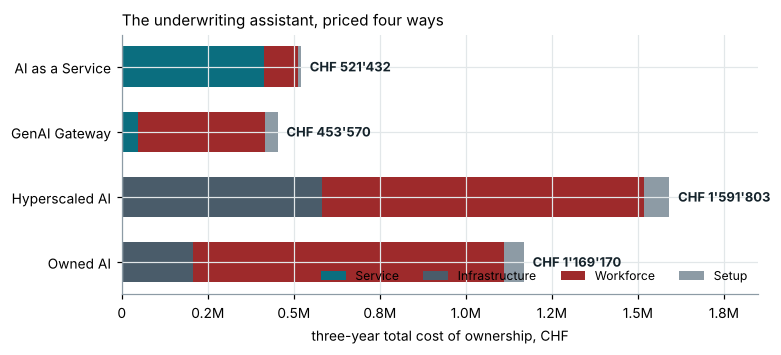

In [7]:
fig, ax = plt.subplots(figsize=(7.2, 3.3))
cats = [("service", "Service", TEAL), ("infra", "Infrastructure", SLATE),
        ("workforce", "Workforce", RED), ("setup", "Setup", "#8d9ba5")]
left = np.zeros(4)
x = np.arange(4)
for key, lab, col in cats:
    v = np.array([opts[k][key] for k in KINDS])
    ax.barh(x, v, left=left, color=col, label=lab, height=.62)
    left += v
for i, k in enumerate(KINDS):
    ax.text(opts[k]["total"] + 25000, i, chf(opts[k]["total"]), va="center", fontsize=8.5,
            fontweight="bold", color=INK)
ax.set_yticks(x, [INFRA[k] for k in KINDS])
ax.invert_yaxis(); ax.set_xlim(0, 1.85e6)
ax.xaxis.set_major_formatter(lambda v, p: f"{v/1e6:.1f}M" if v else "0")
ax.set_xlabel("three-year total cost of ownership, CHF")
ax.set_title("The underwriting assistant, priced four ways", loc="left", fontsize=10)
ax.legend(frameon=False, fontsize=8, ncols=4, loc="lower right")
plt.tight_layout(); plt.show()

## 6 · Workforce

The report's central claim is that staff, not the vendor bill, decide the choice. This section
prints the pensum behind each model and the monthly staff gap that a move to GPUs would have
to earn back.

In [8]:
print(f"{'':<18}{'early':>8}{'mid':>8}{'long':>8}   roles")
for k in KINDS:
    tot = [sum(f[i] for f in FTE[k].values()) for i in range(3)]
    print(f"{INFRA[k]:<18}{tot[0]:>7.0%}{tot[1]:>8.0%}{tot[2]:>8.0%}   "
          + " · ".join(ROLE[r] for r in FTE[k]))

steady = lambda k: sum(f[2] * SALARY[r] for r, f in FTE[k].items())
gap_hyper = steady("hyper") - steady("gateway")
gap_owned = steady("owned") - steady("gateway")
print(f"\nSteady-state staff, CHF a month")
for k in KINDS:
    print(f"  {INFRA[k]:<18}{chf(steady(k)):>12}")
print(f"\nHyperscaled over Gateway : {chf(gap_hyper)} a month  (report: about CHF 24,200)")
print(f"Owned over Gateway       : {chf(gap_owned)} a month")
blend = (5 * TIERS[2]["price_in"] + TIERS[2]["price_out"]) / 6
print(f"\nAt a blended CHF {blend:.2f} per million tokens, that staff gap alone buys "
      f"{gap_hyper/blend/1e3:,.1f} bn tokens of API a month.")

                     early     mid    long   roles
AI as a Service       30%     30%     30%   Prompt engineer
GenAI Gateway         50%     90%    100%   AI engineer · Application developer
Hyperscaled AI       140%    220%    300%   MLOps engineer · Cloud engineer · Site reliability engineer · Application developer
Owned AI             130%    220%    300%   MLOps engineer · Site reliability engineer · Application developer

Steady-state staff, CHF a month
  AI as a Service      CHF 2'733
  GenAI Gateway       CHF 12'558
  Hyperscaled AI      CHF 36'736
  Owned AI            CHF 36'012

Hyperscaled over Gateway : CHF 24'177 a month  (report: about CHF 24,200)
Owned over Gateway       : CHF 23'454 a month

At a blended CHF 3.81 per million tokens, that staff gap alone buys 6.3 bn tokens of API a month.


## 7 · The three use cases — Chapter 5.5

The same model, applied to the report's three applications. Data sensitivity is applied before
cost: client-identifying data rules out the two shared options whatever they cost (Chapter 2.3).

In [9]:
CASES = [
 dict(key="simple",  label="Policy-wording assistant", tier=1, sens="none",
      users=5000, tasks_per_day=3, tokens_in=1500,  tokens_out=300,  seats=0),
 dict(key="medium",  label="Underwriting assistant",   tier=2, sens="confidential",
      users=300,  tasks_per_day=20, tokens_in=5000,  tokens_out=1000, seats=300),
 dict(key="complex", label="Claims-handling platform", tier=3, sens="client-identifying",
      users=40,   tasks_per_day=4, tokens_in=20000, tokens_out=2000, seats=0)]

eligible = lambda s: ["hyper", "owned"] if s == "client-identifying" else KINDS

CASE = {}
for c in CASES:
    r = month_rows(c["users"], c["tasks_per_day"], c["tokens_in"], c["tokens_out"])
    o = {k: run_option(k, r, c["tier"], c["seats"] if k == "aiaas" else 0) for k in KINDS}
    CASE[c["key"]] = dict(cfg=c, rows=r, opts=o)
    ok = eligible(c["sens"])
    best = min(ok, key=lambda k: o[k]["total"])
    print(f"{c['label']:<26} tier {c['tier']} · {c['sens']}")
    for k in KINDS:
        mark = "  ←" if k == best else ("   (ruled out)" if k not in ok else "")
        print(f"    {INFRA[k]:<18}{chf(o[k]['total']):>14}{mark}")
    print()

Policy-wording assistant   tier 1 · none
    AI as a Service      CHF 462'418
    GenAI Gateway        CHF 409'374  ←
    Hyperscaled AI     CHF 1'130'975
    Owned AI           CHF 1'055'138

Underwriting assistant     tier 2 · confidential
    AI as a Service      CHF 521'432
    GenAI Gateway        CHF 453'570  ←
    Hyperscaled AI     CHF 1'591'803
    Owned AI           CHF 1'169'170

Claims-handling platform   tier 3 · client-identifying
    AI as a Service      CHF 115'146   (ruled out)
    GenAI Gateway        CHF 424'902   (ruled out)
    Hyperscaled AI     CHF 4'084'299
    Owned AI           CHF 1'380'598  ←



## 8 · Economy of scale — Chapter 6.4

Owned hardware is bought in whole servers, so what decides the economics is not how much
traffic there is but how evenly it is spread. Two ways of running the same hardware:

* **Provisioned for peak.** A server sized for the busiest second can only be loaded to
  $1/\text{PEAK}$ on average, and only during working hours.
* **Kept busy.** Work batched into the idle hours, so the server runs every hour of the month.

In [10]:
served_peak = lambda t: TIERS[t]["vm_tok_s"] / PEAK * WORK_SECONDS * WORK_DAYS / 1e6  # M/month
served_flat = lambda t: TIERS[t]["vm_tok_s"] * HOURS * 3600 / 1e6                     # M/month

t = 2
print(f"One Tier 2 server, millions of tokens a month")
print(f"  provisioned for peak : {served_peak(t):>9,.0f}   →  CHF {owned_month(t)/served_peak(t):>5.2f} per million")
print(f"  kept busy            : {served_flat(t):>9,.0f}   →  CHF {owned_month(t)/served_flat(t):>5.2f} per million")
print(f"  gateway, blended 5:1 : {'':>9}      CHF {blend:>5.2f} per million")

def scale_at(rows, tier, N):
    # Three-year cost with N applications of this size sharing the stack.
    om = owned_month(tier)
    gw = SETUP["gateway"]; pk = bz = SETUP["owned"]
    flat = served_flat(tier)
    for r in rows:
        wg = sum(f[r["phase"]] * SALARY[x] for x, f in FTE["gateway"].items())
        wo = sum(f[r["phase"]] * SALARY[x] for x, f in FTE["owned"].items())
        gw += (r["tokens_in"] * N / 1e6 * TIERS[tier]["price_in"]
             + r["tokens_out"] * N / 1e6 * TIERS[tier]["price_out"]) + wg
        pk += max(1, math.ceil(r["peak"] * N / TIERS[tier]["vm_tok_s"])) * om + wo
        bz += max(1, math.ceil((r["monthly"] * N / 1e6) / flat)) * om + wo
    return gw, pk, bz

def crossover(rows, tier, idx, limit=400):
    for N in range(1, limit + 1):
        c = scale_at(rows, tier, N)
        if c[idx] < c[0]:
            return N
    return None

x_peak = crossover(rows, 2, 1)
x_busy = crossover(rows, 2, 2)
print(f"\nApplications needed before Owned AI beats the gateway")
print(f"  provisioned for peak : {x_peak if x_peak else 'never'}")
print(f"  kept busy            : {x_busy}×")

One Tier 2 server, millions of tokens a month
  provisioned for peak :       507   →  CHF  8.54 per million
  kept busy            :     6,307   →  CHF  0.69 per million
  gateway, blended 5:1 :                CHF  3.81 per million

Applications needed before Owned AI beats the gateway
  provisioned for peak : never
  kept busy            : 17×


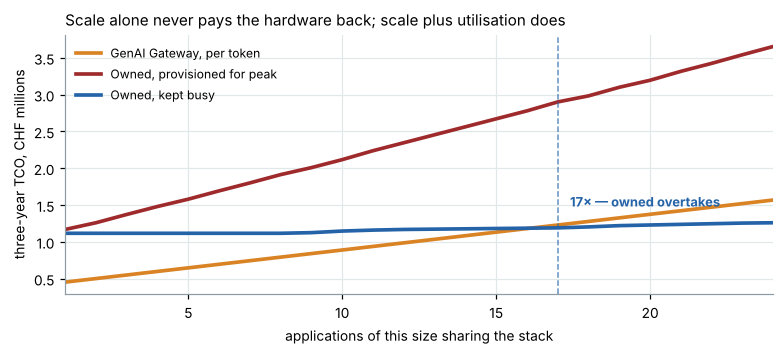

In [11]:
N = np.arange(1, 25)
curves = np.array([scale_at(rows, 2, int(n)) for n in N])
fig, ax = plt.subplots(figsize=(7.2, 3.3))
for i, (lab, col) in enumerate([("GenAI Gateway, per token", AMBER),
                                ("Owned, provisioned for peak", RED),
                                ("Owned, kept busy", BLUE)]):
    ax.plot(N, curves[:, i] / 1e6, color=col, lw=2.4, label=lab)
ax.axvline(x_busy, color=BLUE, ls="--", lw=1, alpha=.7)
ax.annotate(f"{x_busy}× — owned overtakes", (x_busy, curves[x_busy - 1, 2] / 1e6),
            textcoords="offset points", xytext=(8, 14), color=BLUE,
            fontsize=8.5, fontweight="bold")
ax.set(xlabel="applications of this size sharing the stack",
       ylabel="three-year TCO, CHF millions", xlim=(1, 24))
ax.set_title("Scale alone never pays the hardware back; scale plus utilisation does",
             loc="left", fontsize=10)
ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

## 9 · The blended path

Rather than one infrastructure for three years, the cheapest option in each adoption phase,
with the cost of changing between them counted. A migration is priced as the full build cost of
the target stack (Annex H.4): the prompts, the evaluation set and the grounding documents carry
over, the serving layer and the monitoring do not.

In [12]:
def blended_path(case):
    o, sens = case["opts"], case["cfg"]["sens"]
    ok = eligible(sens)
    phases, steps, build, prev = [], [], 0.0, None
    for i in range(3):
        cand = {k: next(b for b in o[k]["by_phase"] if b["idx"] == i) for k in ok}
        run = {k: b["service"] + b["infra"] + b["workforce"] for k, b in cand.items()}
        best = min(run, key=run.get)
        if best != prev:
            steps.append((i, prev, best, SETUP[best])); build += SETUP[best]; prev = best
        phases.append((i, best, run[best], cand[best]["months"]))
    total = sum(p[2] for p in phases) + build
    single = min(ok, key=lambda k: o[k]["total"])
    return phases, steps, build, total, single, o[single]["total"]

for key in ("simple", "medium", "complex"):
    ph, st, build, total, single, single_total = blended_path(CASE[key])
    name = CASE[key]["cfg"]["label"]
    print(f"{name}")
    print("   path    : " + " → ".join(f"{INFRA[p[1]]} ({p[3]}m)" for p in ph))
    print(f"   total   : {chf(total)}   (build and migration {chf(build)})")
    print(f"   best single option: {INFRA[single]} {chf(single_total)}"
          f"   → switching saves {chf(single_total - total)}")
    for i, frm, to, cost in st:
        if frm:
            print(f"   migration at phase {i+1}: {INFRA[frm]} → {INFRA[to]}, {chf(cost)}")
    print()

Policy-wording assistant
   path    : AI as a Service (9m) → GenAI Gateway (22m) → GenAI Gateway (5m)
   total   : CHF 399'988   (build and migration CHF 46'646)
   best single option: GenAI Gateway CHF 409'374   → switching saves CHF 9'386
   migration at phase 2: AI as a Service → GenAI Gateway, CHF 37'535

Underwriting assistant
   path    : GenAI Gateway (9m) → GenAI Gateway (22m) → GenAI Gateway (5m)
   total   : CHF 453'570   (build and migration CHF 37'535)
   best single option: GenAI Gateway CHF 453'570   → switching saves CHF 0

Claims-handling platform
   path    : Owned AI (9m) → Owned AI (22m) → Owned AI (5m)
   total   : CHF 1'380'598   (build and migration CHF 59'605)
   best single option: Owned AI CHF 1'380'598   → switching saves CHF 0



## 10 · Assertions

Every figure published in the report and in the presentation, checked against what this
notebook computes. The cell raises if any one of them disagrees.

In [13]:
med = CASE["medium"]["opts"]
sim, cmx = CASE["simple"]["opts"], CASE["complex"]["opts"]

CHECKS = [
 # (what, computed, published, tolerance)
 ("Phase lengths, months",            lengths,                       [9, 22, 5],  0),
 ("Adopters at month 36",             last["adopters"],              271,         0),
 ("Peak load, tokens/s",              round(last["peak"]),           3388,        1),
 ("Server-months bought",             sum(servers_for_peak(r, 2) for r in rows), 48, 0),

 ("Azure Tier 1, CHF/month",          TIERS[1]["azure"],             3190,        0),
 ("Azure Tier 2, CHF/month",          TIERS[2]["azure"],             12126,       0),
 ("Azure Tier 3, CHF/month",          TIERS[3]["azure"],             85404,       0),
 ("Owned Tier 1, CHF/month",          owned_month(1),                2470,        1),
 ("Owned Tier 2, CHF/month",          owned_month(2),                4331,        1),
 ("Owned Tier 3, CHF/month",          owned_month(3),                11648,       1),

 ("AI as a Service, 3-year TCO",      med["aiaas"]["total"],         521432,      1),
 ("GenAI Gateway, 3-year TCO",        med["gateway"]["total"],       453570,      1),
 ("Hyperscaled AI, 3-year TCO",       med["hyper"]["total"],         1591803,     1),
 ("Owned AI, 3-year TCO",             med["owned"]["total"],         1169170,     1),
 ("Gateway token bill",               med["gateway"]["service"],     48504,       1),
 ("Gateway workforce incl. setup",    med["gateway"]["workforce"] + med["gateway"]["setup"], 405067, 1),
 ("Hyperscaled infrastructure",       med["hyper"]["infra"],         582048,      1),
 ("Owned infrastructure",             med["owned"]["infra"],         207899,      1),
 ("Owned workforce incl. setup",      med["owned"]["workforce"] + med["owned"]["setup"], 961271, 1),

 ("Staff gap, Hyperscaled − Gateway", gap_hyper,                     24177,       1),
 ("Blended API price, CHF/M",         blend,                         3.81,        .01),
 ("Owned per M, peak-provisioned",    owned_month(2)/served_peak(2), 8.54,        .01),
 ("Owned per M, kept busy",           owned_month(2)/served_flat(2), 0.69,        .01),
 ("Crossover, kept busy",             x_busy,                        17,          0),
 ("Crossover, peak-provisioned",      x_peak,                        None,        0),

 ("Policy-wording, AI as a Service",  sim["aiaas"]["total"],         462418,      1),
 ("Policy-wording, Gateway",          sim["gateway"]["total"],       409374,      1),
 ("Claims, Hyperscaled",              cmx["hyper"]["total"],         4084299,     1),
 ("Claims, Owned",                    cmx["owned"]["total"],         1380598,     1),
]

def agrees(got, want, tol):
    if isinstance(want, list):   return got == want
    if want is None:             return got is None
    if got is None:              return False
    return abs(got - want) <= tol

bad = 0
print(f"{'figure':<36}{'computed':>14}{'published':>14}   ")
print("-" * 68)
for what, got, want, tol in CHECKS:
    ok = agrees(got, want, tol)
    bad += not ok
    fmt = lambda v: ("never" if v is None else
                     str(v) if isinstance(v, (list, int)) else f"{v:,.2f}")
    print(f"{what:<36}{fmt(got if isinstance(got,(list,int)) or got is None else round(got,2)):>14}"
          f"{fmt(want):>14}   {'ok' if ok else 'MISMATCH'}")
print("-" * 68)
print(f"{len(CHECKS) - bad} of {len(CHECKS)} figures reproduced")
assert bad == 0, f"{bad} published figures do not reproduce"

figure                                    computed     published   
--------------------------------------------------------------------
Phase lengths, months                   [9, 22, 5]    [9, 22, 5]   ok
Adopters at month 36                           271           271   ok
Peak load, tokens/s                           3388          3388   ok
Server-months bought                            48            48   ok
Azure Tier 1, CHF/month                       3190          3190   ok
Azure Tier 2, CHF/month                      12126         12126   ok
Azure Tier 3, CHF/month                      85404         85404   ok
Owned Tier 1, CHF/month                   2,470.18          2470   ok
Owned Tier 2, CHF/month                   4,331.23          4331   ok
Owned Tier 3, CHF/month                  11,647.96         11648   ok
AI as a Service, 3-year TCO             521,431.80        521432   ok
GenAI Gateway, 3-year TCO               453,570.37        453570   ok
Hyperscaled AI, 3-year 

---

### What this notebook does not do

The figures are assumptions, not quotations: market medians for salaries, estimates for the
staff fractions and the build effort, average coefficients for the adoption curve. Dell does not
publish APEX prices for GPU servers, so the owned cost is built from component prices rather
than from a quote. Azure prices are pay-as-you-go list for Switzerland North; reservations and
negotiated discounts lower them. The point of the model is to show how the decision behaves,
not what it would cost a particular insurer.